# Page: threads, as used by the inline-code-painting plugin

A **thread** is a second line of execution inside the same program. Godot runs the editor (input, drawing, every `_process`) on one **main thread**. Anything slow on that thread freezes the editor, so slow work is moved to a **worker thread** and the result is handed back.

```gdscript
claude_thread = Thread.new()
claude_thread.start(_run_claude.bind(claude_arguments))      # main thread, returns at once

func _run_claude(claude_arguments):                           # worker thread
	var exit_code := OS.execute("/bin/sh", claude_arguments, claude_output, true)
	_on_claude_finished.call_deferred(exit_code, ...)         # hand back to main thread
```

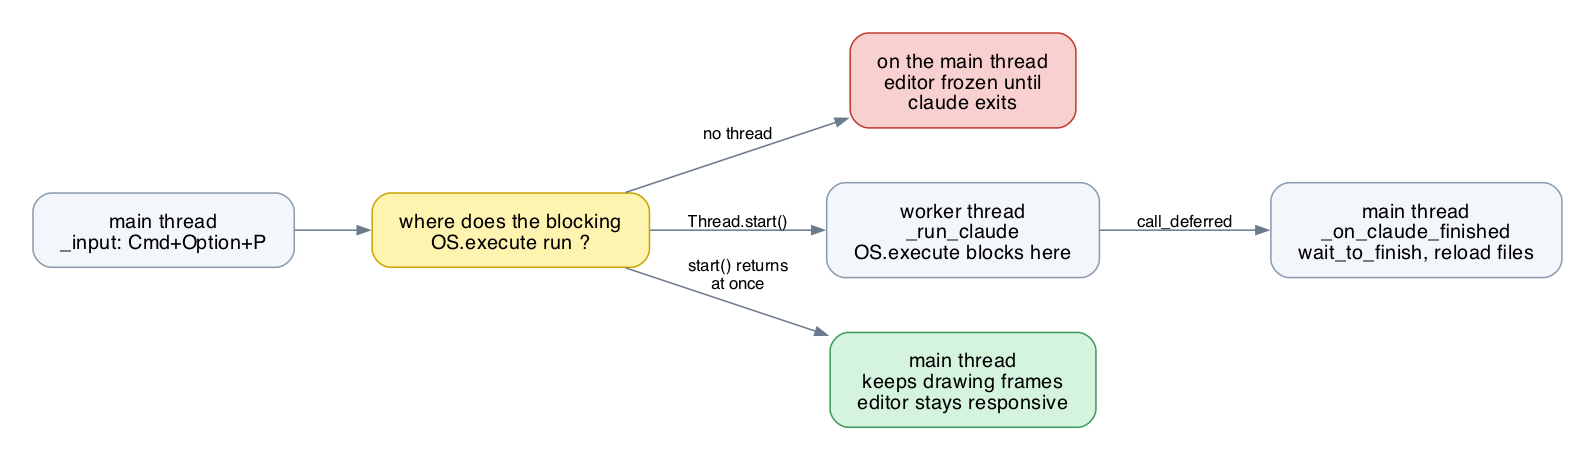

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  press  [label="main thread\n_input: Cmd+Option+P"];
  where  [label="where does the blocking\nOS.execute run ?", fillcolor="#fff3b0", color="#c9a400"];
  frozen [label="on the main thread\neditor frozen until\nclaude exits", fillcolor="#f9d0d0", color="#c0392b"];
  worker [label="worker thread\n_run_claude\nOS.execute blocks here"];
  alive  [label="main thread\nkeeps drawing frames\neditor stays responsive", fillcolor="#d4f4dd", color="#3c9a5f"];
  back   [label="main thread\n_on_claude_finished\nwait_to_finish, reload files"];
  press -> where;
  where -> frozen [label="no thread"];
  where -> worker [label="Thread.start()"];
  where -> alive  [label="start() returns\nat once"];
  worker -> back  [label="call_deferred"];
}
```

</details>

| Thing | What it does | In the plugin |
|---|---|---|
| `Thread.new()` | makes a thread object, not running yet | `claude_thread` |
| `thread.start(callable)` | runs the callable on the new thread, returns at once | `start(_run_claude.bind(...))` |
| `callable.bind(...)` | passes arguments in, so no shared variable is needed | the claude arguments |
| `callable.call_deferred(...)` | queues the call to run on the main thread, at the end of the frame | `_on_claude_finished.call_deferred(...)` |
| `thread.wait_to_finish()` | joins the thread: waits for it to end and cleans it up | first line of `_on_claude_finished`, and `_exit_tree` |
| `thread.is_alive()` | true while the thread's function is still running | not used; `claude_thread != null` is the "busy" check |
| `Mutex` | lock so two threads do not change the same variable at once | not needed, nothing is shared |

**Three rules the plugin follows**

- **Only the main thread touches nodes and the editor.** The scene tree is not thread-safe, so the worker only runs `OS.execute`; the read-only toggle, `reload_open_files()` and `print` all happen in `_on_claude_finished`.
- **Every started thread is joined.** A `Thread` freed without `wait_to_finish()` is an error, which is why `_exit_tree` joins it too (and why closing the editor mid-paint waits for claude).
- **Share nothing.** Data goes in through `bind` and comes out through `call_deferred`, so no `Mutex` is needed. A variable written by both threads would need one.

**Deferred is not the same as threaded.** `call_deferred` does not start a thread; it only postpones a call to later in the same frame, on the main thread. The plugin uses it twice: once to get off the worker thread, and once on `reload_open_files` so `plugin.gd` is not reloaded while one of its own functions is still running.
